     iteration      loss  learning_rate  grad_norm  step_ok  gpu_memory_gb
231        221  6.614688         0.0003   0.627311     True      14.605025
232        222  6.336536         0.0003   0.710660     True      14.605025
233        223  6.399528         0.0003   0.553379     True      14.605025
234        224  6.418162         0.0003   0.634380     True      14.605025
235        225  6.471585         0.0003   0.548782     True      14.605025


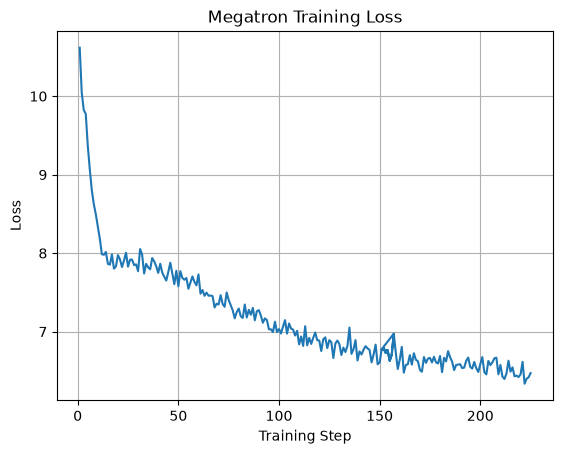

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("logs/training_l.csv")

print(df.tail())

plt.plot(df["iteration"], df["loss"])
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Megatron Training Loss")
plt.grid(True)
plt.show()

In [3]:
import os
import sys
import json
import socket
import subprocess

# ============================================================
# 1. CONFIGURATION — CHANGE THESE
# ============================================================

MODEL_SIZES = {
    "l": {
        "d_model": 1280,
        "d_ff": 5120,
        "num_layers": 36,
        "num_heads": 20,
    },
    "xl": {
        "d_model": 2560,
        "d_ff": 10240,
        "num_layers": 32,
        "num_heads": 32,
    },
}

MODEL_SIZE = "l"          # Choose "l" or "xl"
STEP = 150                # Checkpoint step to test

PROMPT = "Once upon a time"
MAX_NEW_TOKENS = 100

TP_SIZE = 2
PP_SIZE = 1
VOCAB_SIZE = 32000
CONTEXT_LENGTH = 1024

CHECKPOINT_DIR = f"checkpoints_{MODEL_SIZE}"
TOKENIZER_PATH = "../tokenizer_02/fineweb_bpe_32k.json"

# Check that both checkpoint shards exist.
for rank in range(TP_SIZE):
    path = (
        f"{CHECKPOINT_DIR}/step_{STEP:08d}/"
        f"rank_{rank}.pt"
    )
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing checkpoint: {path}")

# ============================================================
# 2. CODE EXECUTED ON BOTH GPUs
# ============================================================

worker_code = r'''
import os
import json
import torch
import torch.distributed as dist

from tokenizers import Tokenizer
from megatron.core import parallel_state
from megatron.core.tensor_parallel.random import (
    model_parallel_cuda_manual_seed,
    get_cuda_rng_tracker,
)
from megatron.core.tensor_parallel.mappings import (
    gather_from_tensor_model_parallel_region,
)
from model_block import build_llama_model

rank = int(os.environ["RANK"])
local_rank = int(os.environ["LOCAL_RANK"])

device = torch.device(f"cuda:{local_rank}")
torch.cuda.set_device(device)

dist.init_process_group(
    backend="nccl",
    init_method="env://",
    device_id=device,
)

try:
    # --------------------------------------------------------
    # Initialize Megatron tensor parallelism
    # --------------------------------------------------------

    parallel_state.initialize_model_parallel(
        tensor_model_parallel_size=2,
        pipeline_model_parallel_size=1,
    )

    # Required before building TP model weights.
    model_parallel_cuda_manual_seed(1234)

    rng_states = get_cuda_rng_tracker().get_states()

    assert "model-parallel-rng" in rng_states, (
        "Megatron model-parallel RNG was not initialized"
    )

    # --------------------------------------------------------
    # Build selected model
    # --------------------------------------------------------

    model_config = json.loads(os.environ["MODEL_CONFIG"])
    vocab_size = int(os.environ["VOCAB_SIZE"])
    context_length = int(os.environ["CONTEXT_LENGTH"])

    model = build_llama_model(
        model_config,
        vocab_size,
        2,
        1,
        context_length,
    ).to(device)

    # --------------------------------------------------------
    # Load this GPU's checkpoint shard
    # --------------------------------------------------------

    checkpoint_dir = os.environ["CHECKPOINT_DIR"]
    step = int(os.environ["CHECKPOINT_STEP"])

    checkpoint_path = (
        f"{checkpoint_dir}/step_{step:08d}/"
        f"rank_{rank}.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    state = checkpoint["model"]

    # Remove DDP prefix if present.
    state = {
        k.removeprefix("module."): v
        for k, v in state.items()
    }

    model.load_state_dict(state, strict=True)
    del checkpoint, state

    model.eval()

    print(
        f"[Rank {rank}] Loaded {checkpoint_path}",
        flush=True,
    )

    # --------------------------------------------------------
    # Tokenize prompt
    # --------------------------------------------------------

    tokenizer = Tokenizer.from_file(
        os.environ["TOKENIZER_PATH"]
    )

    eod_id = tokenizer.token_to_id("<|endoftext|>")

    prompt = os.environ["INFERENCE_PROMPT"]
    max_new_tokens = int(os.environ["MAX_NEW_TOKENS"])

    prompt_ids = tokenizer.encode(
        prompt,
        add_special_tokens=False,
    ).ids

    if not prompt_ids:
        raise ValueError("Prompt produced no tokens.")

    if len(prompt_ids) >= context_length:
        raise ValueError("Prompt is too long for the model context.")

    generated = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device,
    )

    # --------------------------------------------------------
    # Greedy generation
    # --------------------------------------------------------

    with torch.inference_mode():

        for _ in range(max_new_tokens):

            seq_len = generated.shape[1]

            if seq_len > context_length:
                break

            position_ids = torch.arange(
                seq_len,
                device=device,
            ).unsqueeze(0)

            # True means the attention position is masked.
            attention_mask = torch.triu(
                torch.ones(
                    (1, 1, seq_len, seq_len),
                    dtype=torch.bool,
                    device=device,
                ),
                diagonal=1,
            )

            logits = model(
                input_ids=generated,
                position_ids=position_ids,
                attention_mask=attention_mask,
                labels=None,
            )

            # Megatron's output layout may be [S, B, V].
            # For batch size 1, handle both [S, B, V]
            # and [B, S, V] layouts explicitly.
            if logits.shape[0] == seq_len and logits.shape[1] == 1:
                local_logits = logits[-1, :, :]
            elif logits.shape[0] == 1 and logits.shape[1] == seq_len:
                local_logits = logits[:, -1, :]
            else:
                raise RuntimeError(
                    f"Unexpected logits shape: {tuple(logits.shape)}"
                )

            # Gather vocabulary shards across both TP ranks.
            full_logits = gather_from_tensor_model_parallel_region(
                local_logits
            )

            # Greedy decoding.
            next_token = full_logits.argmax(
                dim=-1,
                keepdim=True,
            )

            generated = torch.cat(
                [generated, next_token],
                dim=1,
            )

            if eod_id is not None and next_token.item() == eod_id:
                break

    # --------------------------------------------------------
    # Print output only from rank 0
    # --------------------------------------------------------

    if rank == 0:

        output_ids = generated[
            0, len(prompt_ids):
        ].tolist()

        generated_text = tokenizer.decode(
            output_ids,
            skip_special_tokens=True,
        )

        print("\n" + "=" * 60)
        print("MODEL:", os.environ["MODEL_SIZE"])
        print("CHECKPOINT STEP:", step)
        print("PROMPT:", prompt)
        print("=" * 60)
        print("GENERATED TEXT:\n")
        print(generated_text)
        print("=" * 60, flush=True)

finally:
    if parallel_state.model_parallel_is_initialized():
        parallel_state.destroy_model_parallel()

    dist.destroy_process_group()
'''

# ============================================================
# 3. LAUNCH TWO PROCESSES FROM JUPYTER
# ============================================================

with socket.socket() as sock:
    sock.bind(("127.0.0.1", 0))
    port = sock.getsockname()[1]

base_env = os.environ.copy()

base_env.update({
    "MASTER_ADDR": "127.0.0.1",
    "MASTER_PORT": str(port),
    "WORLD_SIZE": str(TP_SIZE),

    "MODEL_SIZE": MODEL_SIZE,
    "MODEL_CONFIG": json.dumps(MODEL_SIZES[MODEL_SIZE]),

    "CHECKPOINT_DIR": CHECKPOINT_DIR,
    "CHECKPOINT_STEP": str(STEP),

    "TOKENIZER_PATH": TOKENIZER_PATH,
    "INFERENCE_PROMPT": PROMPT,
    "MAX_NEW_TOKENS": str(MAX_NEW_TOKENS),

    "VOCAB_SIZE": str(VOCAB_SIZE),
    "CONTEXT_LENGTH": str(CONTEXT_LENGTH),
})

processes = []

for rank in range(TP_SIZE):

    env = base_env.copy()
    env["RANK"] = str(rank)
    env["LOCAL_RANK"] = str(rank)

    process = subprocess.Popen(
        [sys.executable, "-u", "-c", worker_code],
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

    processes.append(process)

# Both ranks have already been launched.
# Collect their results.
for rank, process in enumerate(processes):

    output, _ = process.communicate()

    print(f"\n{'=' * 20} RANK {rank} {'=' * 20}")
    print(output)
    print("Exit code:", process.returncode)

    if process.returncode != 0:
        print(f"Rank {rank} failed.")


==================== RANK 0 ====================
/usr/local/lib/python3.12/dist-packages/megatron/core/optimizer/__init__.py:25: UserWarning: Transformer Engine and Apex are not installed. Falling back to Torch optimizers.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/megatron/core/distributed/fsdp/src/megatron_fsdp/mixed_precision.py:115: UserWarning: Transformer Engine and Apex are not installed. Falling back to local implementations of multi_tensor_applier and multi_tensor_scale
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/megatron/core/optimizer/optimizer.py:29: UserWarning: Transformer Engine and Apex are not installed. Falling back to local implementations of multi_tensor_applier and multi_tensor_scale
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/megatron/core/optimizer/clip_grads.py:32: UserWarning: Transformer Engine and Apex are not installed. Falling back to local implementations of multi_tensor_applier, multi_tensor_l2norm, and multi_tenso

In [1]:
import subprocess
import sys

worker_code = """
import os
import torch
import torch.distributed as dist

rank = int(os.environ["RANK"])
local_rank = int(os.environ["LOCAL_RANK"])
world_size = int(os.environ["WORLD_SIZE"])

torch.cuda.set_device(local_rank)

dist.init_process_group(
    backend="nccl",
    init_method="env://",
    rank=rank,
    world_size=world_size,
)

print(
    f"Rank {rank}: GPU {torch.cuda.current_device()}",
    flush=True,
)

dist.barrier()
dist.destroy_process_group()
"""

import socket

with socket.socket() as sock:
    sock.bind(("127.0.0.1", 0))
    port = sock.getsockname()[1]

env = os.environ.copy()
env["MASTER_ADDR"] = "127.0.0.1"
env["MASTER_PORT"] = str(port)
env["WORLD_SIZE"] = "2"

processes = []

for rank in range(2):
    rank_env = env.copy()
    rank_env["RANK"] = str(rank)
    rank_env["LOCAL_RANK"] = str(rank)

    process = subprocess.Popen(
        [sys.executable, "-u", "-c", worker_code],
        env=rank_env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )
    processes.append(process)

for rank, process in enumerate(processes):
    output, _ = process.communicate()
    print(f"--- Rank {rank} ---")
    print(output)
    print("Exit code:", process.returncode)

NameError: name 'os' is not defined